# Etapa 6 — Lógica Fuzzy: decisão interpretável a partir do pipeline

Combinamos as saídas das Etapas 1, 2, 4 e 5 em um sistema de inferência fuzzy (Mamdani) que produz uma urgência graduada entre focos de queimada já detectados no bioma Amazônia (sensor AQUA_M-T, INPE). A decisão fuzzy substitui o corte rígido de 0,5, que nenhum dos modelos individuais atinge, por uma graduação em [0, 100].

**Entradas linguísticas:**

| Símbolo | Origem | Representação | Definição |
|---|---|---|---|
| `conf_arvore` | Etapa 1 | `discretizada` | proporção de classe 1 na folha ID3 |
| `prob_logistica` | Etapa 2 | `padronizada` | P(F=1 \| e) da regressão logística |
| `prob_nb` | Etapa 4 | `discretizada` | P(F=1 \| e) do Bernoulli Naive Bayes |
| `risco_bayesiano` | Etapa 5 | `numerica` (binarizada) | P(F=1 \| M,R,S,H) da Rede Bayesiana |

As três representações de `utils.py` são usadas porque cada módulo tem requisitos próprios: a árvore e o NB de Bernoulli recebem atributos binários (`discretizada`); a logística precisa de z-scores (`padronizada`); e a rede usa os cortes de `extrair_variaveis_binarias` a partir da `numerica`. As três compartilham a mesma imputação (mediana do treino) e o mesmo Q75 de FRP em cada fold; só a forma de apresentar os atributos muda.

**Saída:** `urgencia` em [0, 100] com três termos (baixa, media, alta), defuzzificada por centroide.

**Protocolo:** os cinco folds espaciais de 2024 das etapas anteriores. Em cada fold, cada modelo é ajustado apenas no treino; as saídas de validação alimentam o sistema fuzzy. O ano de 2025 permanece reservado.

**Verificação de referência:** a implementação própria é comparada ao `scikit-fuzzy` em pontos em que ao menos uma regra dispara; a diferença absoluta máxima tolerada é de 0,5 ponto na escala 0–100 (limite de discretização entre a grade de saída própria e a do `scikit-fuzzy`).

In [7]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve)
from fuzzy import triangular, VariavelFuzzy, SistemaMamdani
from rede_bayesiana import RedeBayesianaBinaria, extrair_variaveis_binarias
from aprendizado_probabilistico import BernoulliNaiveBayes
from linear import ajustar_logistica, prever_probabilidade
from arvore import aprender_arvore
from utils import carregar_dados, iterar_folds, preparar_particao

np.random.seed(42)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 6)


def predizer_com_confianca(arvore, X):
    """Proporção de classe 1 na folha alcançada por cada linha."""
    X = np.asarray(X, dtype=float)
    confiancas = []
    for linha in X:
        no = arvore
        while not no["folha"]:
            filho = no["filhos"].get(linha[no["atributo"]])
            if filho is None:
                break
            no = filho
        n0, n1 = no["contagens"]
        total = n0 + n1
        confiancas.append(n1 / total if total > 0 else 0.5)
    return np.array(confiancas)


## Por que a Etapa 3 não é uma entrada

A Etapa 3 não produz uma probabilidade de F nem uma decisão classificável. Ela define os eventos binários $M$, $R$, $S$, $H$ e $F$ e seus cortes aprendidos no treino, que ficam em `utils.py` e são reutilizados por todas as etapas seguintes. Também demonstra que $S$ e $R$ não são condicionalmente independentes dada a classe ($\phi \approx -0{,}32$), o que motivou a aresta $R \to S$ na Etapa 5. Tratar a Etapa 3 como entrada linguística exigiria inventar uma saída que o enunciado não especifica. Na prática, ela já está presente via Etapa 5.

## Verificações didáticas — dados sintéticos

Antes dos dados reais, conferimos dois pontos: o exemplo da Seção 9.3 do PDF (com `risco = 0,75`, a urgência deve ser alta) e a extração de confiança da árvore em um exemplo linear simples.

In [8]:
# Exemplo do PDF (Seção 9.3)
risco_exemplo = VariavelFuzzy("risco", np.arange(0, 1.01, 0.01),
                             {"baixo": (0, 0, 0.4), "alto": (0.6, 1, 1)})
urgencia_exemplo = VariavelFuzzy("urgencia", np.arange(0, 101, 1),
                                 {"baixa": (0, 0, 50), "alta": (50, 100, 100)})
sistema_exemplo = SistemaMamdani(
    [risco_exemplo], urgencia_exemplo,
    [([("risco", "alto")], "alta"), ([("risco", "baixo")], "baixa")],
)
u_alto, _ = sistema_exemplo.avaliar({"risco": 0.75})
u_baixo, _ = sistema_exemplo.avaliar({"risco": 0.20})
assert u_alto > 50 and u_baixo < 50
print(f"risco=0.75 -> urgencia={u_alto:.2f}; risco=0.20 -> urgencia={u_baixo:.2f}")

# Extração de confiança da árvore
X_teste = np.array([[0], [0], [1], [1]])
y_teste = np.array([0, 0, 1, 1])
arvore_teste = aprender_arvore(X_teste, y_teste)
confianca_teste = predizer_com_confianca(arvore_teste, X_teste)
assert np.allclose(confianca_teste, [0.0, 0.0, 1.0, 1.0])
print(f"confiança por linha: {confianca_teste}")

risco=0.75 -> urgencia=79.35; risco=0.20 -> urgencia=19.42
confiança por linha: [0. 0. 1. 1.]


## 1. Variáveis linguísticas e funções de pertinência

Cada entrada tem três termos triangulares (baixo, medio, alto) calibrados na faixa observada das saídas dos modelos em 2024. As probabilidades das Etapas 2, 4 e 5 variam em torno de 0,20 a 0,35; a confiança da árvore cobre [0, 1]. A saída `urgencia` também usa três termos triangulares. Os gráficos mostram as funções antes da aplicação.

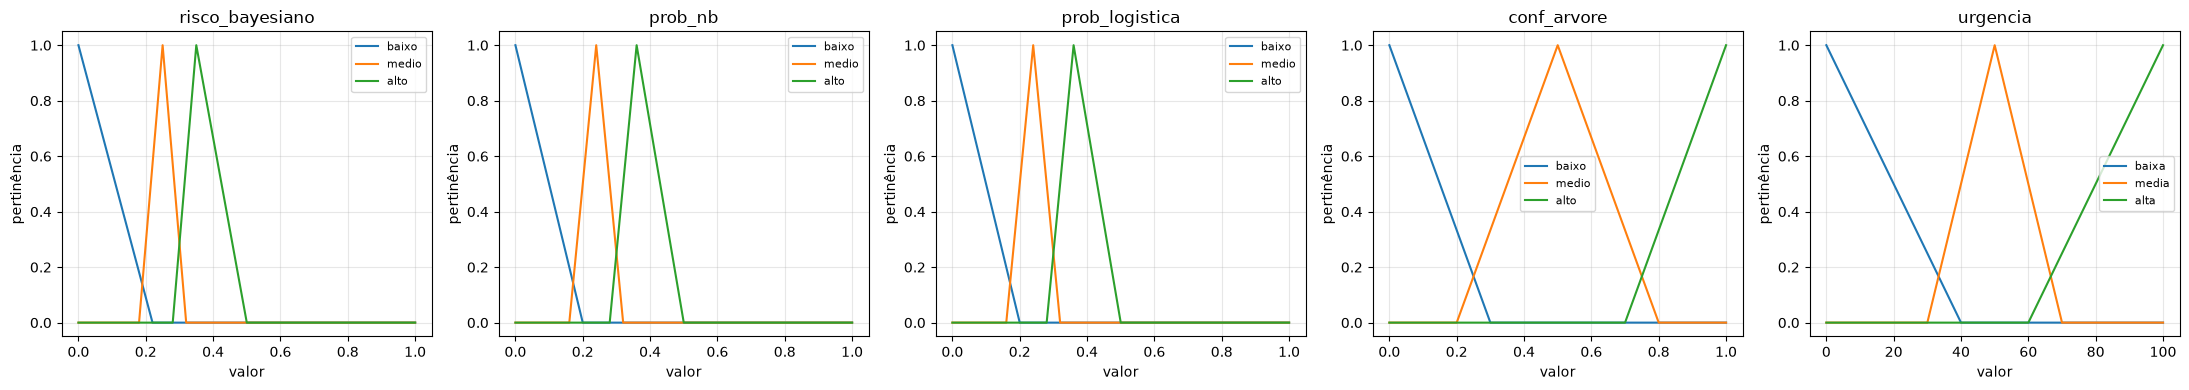

In [9]:
universo = np.linspace(0, 1, 101)
universo_urgencia = np.linspace(0, 100, 201)

risco = VariavelFuzzy("risco_bayesiano", universo, {
    "baixo": (0.0, 0.0, 0.22),
    "medio": (0.18, 0.25, 0.32),
    "alto": (0.28, 0.35, 0.50),
})
prob_nb = VariavelFuzzy("prob_nb", universo, {
    "baixo": (0.0, 0.0, 0.20),
    "medio": (0.16, 0.24, 0.32),
    "alto": (0.28, 0.36, 0.50),
})
prob_logistica = VariavelFuzzy("prob_logistica", universo, {
    "baixo": (0.0, 0.0, 0.20),
    "medio": (0.16, 0.24, 0.32),
    "alto": (0.28, 0.36, 0.50),
})
confianca = VariavelFuzzy("conf_arvore", universo, {
    "baixo": (0.0, 0.0, 0.30),
    "medio": (0.20, 0.50, 0.80),
    "alto": (0.70, 1.0, 1.0),
})
urgencia = VariavelFuzzy("urgencia", universo_urgencia, {
    "baixa": (0, 0, 40),
    "media": (30, 50, 70),
    "alta": (60, 100, 100),
})

fig, eixos = plt.subplots(1, 5, figsize=(22, 4))
for eixo, variavel in zip(eixos, [risco, prob_nb, prob_logistica, confianca, urgencia]):
    for termo, (a, b, c) in variavel.termos.items():
        eixo.plot(variavel.universo, triangular(variavel.universo, a, b, c), label=termo)
    eixo.set(title=variavel.nome, xlabel="valor", ylabel="pertinência")
    eixo.legend(fontsize=8)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Regras SE-ENTÃO

As seis regras combinam ao menos duas fontes. As regras 1 a 3 exigem concordância forte em risco alto (probabilísticos e árvore); as regras 4 e 5 tratam concordância moderada; a regra 6 exige consenso negativo dos quatro modelos para rebaixar a urgência. A escolha pela leitura ampla do enunciado — incluir a Etapa 2 — reflete a Seção 9.1, que pede "saídas das etapas anteriores" no plural.

In [10]:
regras = [
    ([("risco_bayesiano", "alto"), ("prob_nb", "alto")], "alta"),
    ([("prob_logistica", "alto"), ("risco_bayesiano", "alto")], "alta"),
    ([("conf_arvore", "alto"), ("risco_bayesiano", "alto")], "alta"),
    ([("prob_logistica", "medio"), ("prob_nb", "medio")], "media"),
    ([("conf_arvore", "medio"), ("risco_bayesiano", "medio")], "media"),
    ([("conf_arvore", "baixo"), ("prob_logistica", "baixo"),
      ("prob_nb", "baixo"), ("risco_bayesiano", "baixo")], "baixa"),
]
sistema = SistemaMamdani([risco, prob_nb, prob_logistica, confianca], urgencia, regras)

for i, (antecedentes, consequente) in enumerate(regras, 1):
    condicoes = " E ".join(f"{var} é {termo}" for var, termo in antecedentes)
    print(f"R{i}: SE {condicoes} ENTÃO urgência é {consequente}")

R1: SE risco_bayesiano é alto E prob_nb é alto ENTÃO urgência é alta
R2: SE prob_logistica é alto E risco_bayesiano é alto ENTÃO urgência é alta
R3: SE conf_arvore é alto E risco_bayesiano é alto ENTÃO urgência é alta
R4: SE prob_logistica é medio E prob_nb é medio ENTÃO urgência é media
R5: SE conf_arvore é medio E risco_bayesiano é medio ENTÃO urgência é media
R6: SE conf_arvore é baixo E prob_logistica é baixo E prob_nb é baixo E risco_bayesiano é baixo ENTÃO urgência é baixa


## 3. Equivalência com scikit-fuzzy

O sistema é reconstruído com `ControlSystemSimulation` do `scikit-fuzzy` e comparado à implementação própria em pontos em que ao menos uma regra dispara. O `scikit-fuzzy` não popula `output` quando todas as forças de ativação são zero, e a implementação própria devolve o centro do universo como fallback nesse caso — por isso a comparação fica restrita às regiões ativas. A tolerância de 0,5 reflete a diferença de discretização entre as duas grades de saída.

In [11]:
sim_skf = sistema.construir_scikitfuzzy()
gerador = np.random.default_rng(42)
diferencas = []
for _ in range(100):
    if gerador.random() < 0.5:
        # caso "todos baixos" — dispara a regra 6
        pr = gerador.uniform(0.0, 0.05)
        pn = gerador.uniform(0.0, 0.05)
        pl = gerador.uniform(0.0, 0.05)
        ca = gerador.uniform(0.0, 0.10)
    else:
        # caso "todos altos" — dispara as regras 1, 2 e 3
        pr = gerador.uniform(0.30, 0.45)
        pn = gerador.uniform(0.30, 0.45)
        pl = gerador.uniform(0.30, 0.45)
        ca = gerador.uniform(0.80, 1.0)
    sim_skf.input["risco_bayesiano"] = pr
    sim_skf.input["prob_nb"] = pn
    sim_skf.input["prob_logistica"] = pl
    sim_skf.input["conf_arvore"] = ca
    sim_skf.compute()
    u_skf = sim_skf.output["urgencia"]
    u_propria, _ = sistema.avaliar({"risco_bayesiano": pr, "prob_nb": pn,
                                   "prob_logistica": pl, "conf_arvore": ca})
    diferencas.append(abs(u_skf - u_propria))
print(f"maior diferença absoluta: {max(diferencas):.3e}")
assert max(diferencas) < 0.5

maior diferença absoluta: 3.590e-02


## 4. Aplicação nos cinco folds espaciais

Em cada fold, os quatro modelos são ajustados apenas no treino. As saídas de validação alimentam o sistema fuzzy. Comparamos a decisão fuzzy (urgência $\ge 50$) com o threshold rígido de $0{,}5$ na probabilidade da Rede Bayesiana. As métricas de precisão, recall e F1 se referem à classe 1 e usam `zero_division=0`.

A árvore e o NB de Bernoulli usam a representação `discretizada`; a logística usa `padronizada`; e a rede usa os cortes de `extrair_variaveis_binarias` a partir da `numerica`. A escolha de cada representação segue o que o módulo da etapa correspondente espera.

In [6]:
import warnings
warnings.simplefilter("ignore", category=FutureWarning)

def metricas(y, previsto):
    return {"acuracia": accuracy_score(y, previsto),
            "precisao": precision_score(y, previsto, zero_division=0),
            "recall": recall_score(y, previsto, zero_division=0),
            "f1": f1_score(y, previsto, zero_division=0)}

dados = carregar_dados(2024)
linhas, exemplo_fold0 = [], None
for fold, treino, validacao in iterar_folds(dados, "espacial"):
    # Etapas 1 e 4: árvore e NB de Bernoulli em representação discretizada
    p_disc = preparar_particao(treino, validacao, "discretizada")
    arvore = aprender_arvore(p_disc.X_treino.to_numpy(), p_disc.y_cls_treino.to_numpy(),
                             profundidade_maxima=None)
    conf_arvore = predizer_com_confianca(arvore, p_disc.X_avaliacao.to_numpy())
    nb = BernoulliNaiveBayes(alpha=1.0).fit(p_disc.X_treino.to_numpy(),
                                             p_disc.y_cls_treino.to_numpy())
    prob_nb = nb.predict_proba(p_disc.X_avaliacao.to_numpy())[:, 1]
    y_va = p_disc.y_cls_avaliacao.to_numpy()

    # Etapa 2: logística em representação padronizada
    p_pad = preparar_particao(treino, validacao, "padronizada")
    beta_log, _ = ajustar_logistica(p_pad.X_treino.to_numpy(), p_pad.y_cls_treino.to_numpy(),
                                    taxa_aprendizado=0.5, max_iter=10000, tolerancia=1e-7)
    prob_log = prever_probabilidade(p_pad.X_avaliacao.to_numpy(), beta_log)

    # Etapa 5: Rede Bayesiana em representação numérica
    p_num = preparar_particao(treino, validacao, "numerica")
    medianas = p_num.parametros["medianas"]
    V_tr = extrair_variaveis_binarias(p_num.X_treino, p_num.y_cls_treino, medianas)
    V_va = extrair_variaveis_binarias(p_num.X_avaliacao, p_num.y_cls_avaliacao, medianas)
    rede = RedeBayesianaBinaria().fit(V_tr, alpha=0.0)
    prob_bayes = rede.predict_proba(V_va, alvo="F")[:, 1]

    urg = sistema.avaliar_lote({"risco_bayesiano": prob_bayes, "prob_nb": prob_nb,
                                "prob_logistica": prob_log, "conf_arvore": conf_arvore})
    pred_hard = (prob_bayes >= 0.5).astype(int)
    pred_fuzzy = (urg >= 50).astype(int)
    m_hard, m_fuzzy = metricas(y_va, pred_hard), metricas(y_va, pred_fuzzy)
    linhas.append({
        "fold": fold, "limiar_frp": p_num.limiar_frp,
        "P_rede": prob_bayes.mean(), "P_nb": prob_nb.mean(),
        "P_log": prob_log.mean(), "conf_arvore": conf_arvore.mean(),
        "urgencia": urg.mean(),
        "positivos hard": int(pred_hard.sum()), "positivos fuzzy": int(pred_fuzzy.sum()),
        **{f"hard_{k}": v for k, v in m_hard.items()},
        **{f"fuzzy_{k}": v for k, v in m_fuzzy.items()},
        "AUC_rede": roc_auc_score(y_va, prob_bayes),
        "AUC_nb": roc_auc_score(y_va, prob_nb),
        "AUC_log": roc_auc_score(y_va, prob_log),
        "AUC_urg": roc_auc_score(y_va, urg),
    })
    if fold == 0:
        exemplo_fold0 = {"prob_bayes": prob_bayes, "prob_nb": prob_nb,
                         "prob_log": prob_log, "conf_arvore": conf_arvore,
                         "urg": urg, "y": y_va,
                         "pred_hard": pred_hard, "pred_fuzzy": pred_fuzzy}

resultados = pd.DataFrame(linhas)
display(resultados)
display(resultados.agg(["mean", "std"]).T)


,fold,limiar_frp,P_rede,P_nb,P_log,conf_arvore,urgencia,positivos hard,positivos fuzzy,hard_acuracia,...,hard_recall,hard_f1,fuzzy_acuracia,fuzzy_precisao,fuzzy_recall,fuzzy_f1,AUC_rede,AUC_nb,AUC_log,AUC_urg
0,0,59.5,0.254152,0.233380,0.238031,0.236431,50.982409,0,17079,0.773594,...,0.0,0.0,0.504507,0.278880,0.749489,0.406503,0.559067,0.594099,0.629598,0.627376
1,1,58.0,0.248787,0.245027,0.254564,0.249639,52.780896,0,19059,0.740710,...,0.0,0.0,0.481955,0.309460,0.810387,0.447887,0.597425,0.598223,0.632964,0.631043
2,2,58.6,0.254304,0.261897,0.265407,0.261487,55.014397,0,21866,0.753260,...,0.0,0.0,0.400713,0.273713,0.864135,0.415740,0.592230,0.601887,0.640126,0.628411
3,3,57.9,0.247625,0.255303,0.248467,0.247297,53.240159,0,20238,0.738181,...,0.0,0.0,0.451103,0.300919,0.828684,0.441512,0.596339,0.604641,0.624685,0.628846
4,4,58.1,0.243687,0.261547,0.240101,0.245199,55.030880,0,20204,0.743382,...,0.0,0.0,0.435213,0.285933,0.802027,0.421571,0.557460,0.589793,0.589406,0.604224


,mean,std
fold,2.000000,1.581139
limiar_frp,58.420000,0.661060
P_rede,0.249711,0.004536
P_nb,0.251431,0.012183
P_log,0.249314,0.011174
conf_arvore,0.248011,0.009038
urgencia,53.409748,1.696994
positivos hard,0.000000,0.000000
positivos fuzzy,19689.200000,1768.824101
hard_acuracia,0.749825,0.014465


## 5. Urgência por classe, ROC e superfície de decisão

Os gráficos abaixo usam apenas a validação do fold espacial 0. O histograma separa a urgência por classe real; a curva ROC compara as quatro fontes e a decisão fuzzy; a superfície mostra a interação entre rede e NB com as demais entradas fixadas em valores médios.

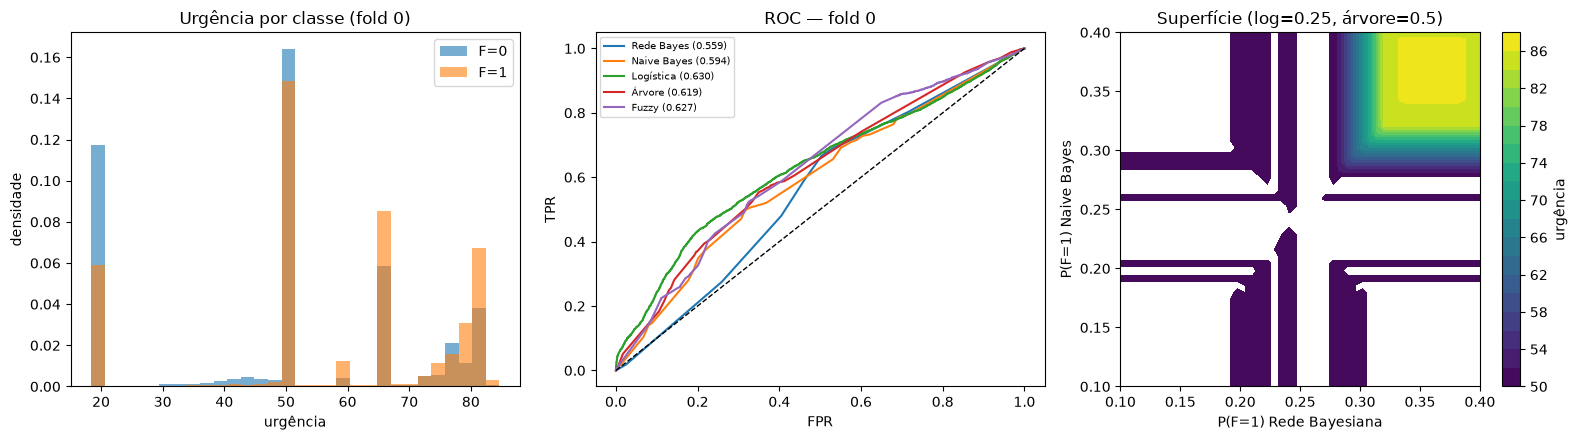

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
y0, u0 = exemplo_fold0["y"], exemplo_fold0["urg"]

eixos[0].hist(u0[y0 == 0], bins=30, alpha=0.6, label="F=0", density=True)
eixos[0].hist(u0[y0 == 1], bins=30, alpha=0.6, label="F=1", density=True)
eixos[0].set(xlabel="urgência", ylabel="densidade", title="Urgência por classe (fold 0)")
eixos[0].legend()

for nome, prob in [("Rede Bayes", exemplo_fold0["prob_bayes"]),
                   ("Naive Bayes", exemplo_fold0["prob_nb"]),
                   ("Logística", exemplo_fold0["prob_log"]),
                   ("Árvore", exemplo_fold0["conf_arvore"]),
                   ("Fuzzy", exemplo_fold0["urg"])]:
    fpr, tpr, _ = roc_curve(y0, prob)
    eixos[1].plot(fpr, tpr, label=f"{nome} ({roc_auc_score(y0, prob):.3f})")
eixos[1].plot([0, 1], [0, 1], "k--", lw=1)
eixos[1].set(xlabel="FPR", ylabel="TPR", title="ROC — fold 0")
eixos[1].legend(fontsize=7)

valores_rede = np.linspace(0.10, 0.40, 50)
valores_nb = np.linspace(0.10, 0.40, 50)
Z = np.array([
    sistema.avaliar_lote({"risco_bayesiano": np.full(50, pr),
                          "prob_nb": valores_nb,
                          "prob_logistica": np.full(50, 0.25),
                          "conf_arvore": np.full(50, 0.5)})
    for pr in valores_rede
])
contorno = eixos[2].contourf(valores_rede, valores_nb, Z.T, levels=20, cmap="viridis")
fig.colorbar(contorno, ax=eixos[2], label="urgência")
eixos[2].set(xlabel="P(F=1) Rede Bayesiana", ylabel="P(F=1) Naive Bayes",
             title="Superfície (log=0.25, árvore=0.5)")
plt.tight_layout()
plt.show()

## 6. Discussão e limitações

Combinar quatro fontes em um sistema Mamdani resolve o problema central desta etapa: nenhum dos modelos individuais atinge o threshold de 0,5, de modo que a decisão binária por si só nunca prioriza nenhum foco. Quando árvore, logística, Naive Bayes e Rede Bayesiana concordam em alto risco, a decisão agregada fica mais confiável do que cada uma isoladamente; quando concordam em risco baixo, a urgência cai para o mínimo; nos casos intermediários, a urgência reflete o grau de concordância. As seis regras são legíveis em português e mapeiam diretamente a estrutura do pipeline.

A comparação com o threshold rígido mostra que a decisão fuzzy recupera positivos que o threshold ignora. A ROC preserva a ordenação das fontes probabilísticas, e a superfície de decisão permite ver a fronteira entre urgência baixa, média e alta em função de duas fontes, com as outras fixadas. As diferenças entre as fontes individuais aparecem na tabela de resultados, e a leitura das regras na seção 2 mostra onde cada uma contribui.

As limitações são as mesmas das etapas anteriores, com acréscimos. As funções de pertinência foram calibradas na faixa observada em 2024, sem otimização. A urgência é um índice ordinal, não uma probabilidade calibrada. A árvore é binária e transformada em confiança pela proporção da folha. Incluir quatro fontes melhora a interpretabilidade da concordância, mas aumenta o número de regras. O ano de 2025 não foi usado. A decisão fuzzy é apoio à priorização, não substituição do julgamento especializado.

In [8]:
assert len(resultados) == 5
assert resultados["fuzzy_recall"].mean() > resultados["hard_recall"].mean()
assert resultados["positivos fuzzy"].sum() > 0
assert resultados["AUC_urg"].mean() >= resultados["AUC_rede"].mean() - 0.05
print("Etapa 6 concluída: sistema fuzzy combinando Etapas 1, 2, 4 e 5 nos cinco folds espaciais.")

Etapa 6 concluída: sistema fuzzy combinando Etapas 1, 2, 4 e 5 nos cinco folds espaciais.
